In [1]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 211, done.
remote: Counting objects: 100% (211/211), done.
remote: Compressing objects: 100% (189/189), done.
remote: Total 211 (delta 43), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (211/211), 29.10 MiB | 10.08 MiB/s, done.
Resolving deltas: 100% (43/43), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['buat_dataset_sintetis.py', 'praproses.py', 'utils_cv.py']


kode 5.1

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from utils_cv import baca, statistik, tampil, kontras_bercak
from praproses import praproses, simpan_param

# Parameter praproses
param = {
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "penapis": "median",
    "kernel": 3
}

simpan_param(param, "../hasil/param_praproses.json")

# Memilih kanal terbaik berdasarkan Bagian 2
KANAL = 2  # Indeks BGR: 0 = B, 1 = G, 2 = R

# Membaca dataset
label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    # Melakukan praproses
    out = praproses(img, param)

    # Menghitung kontras bercak sebelum dan sesudah praproses
    baris.append([
        d.kondisi_cahaya,
        kontras_bercak(img[:, :, KANAL], md, mb),
        kontras_bercak(out[:, :, KANAL], md, mb)
    ])

# Membuat tabel evaluasi
evaluasi = pd.DataFrame(
    baris,
    columns=["kondisi", "KB_sebelum", "KB_sesudah"]
)

print(evaluasi.groupby("kondisi").mean().round(2))

                KB_sebelum  KB_sesudah
kondisi                               
bayangan              4.83        8.03
gelap                 8.49       14.42
kontras_rendah        3.54        4.65
normal                9.05       10.05
terang                6.27        6.01


Pengujian

In [3]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca
from praproses import praproses

os.makedirs("../hasil", exist_ok=True)

# Gunakan parameter yang sama dengan Langkah 5.2
with open("../hasil/param_praproses.json", "r") as f:
    param = json.load(f)

# Gunakan kanal yang sama dengan Langkah 5.2
KANAL = 2

# Membaca label dataset
label = pd.read_csv("../data/sintetis/label.csv")

# Memilih 20 citra sehat: teh_001 sampai teh_020
label["nomor"] = label["nama_file"].str.extract(r"teh_(\d+)").astype(float)

data_sehat = label[
    (label["kelas"] == "sehat") &
    (label["nomor"].between(1, 20))
].sort_values("nomor")

print("Jumlah citra sehat:", len(data_sehat))

baris = []
panel = {}

for _, d in data_sehat.iterrows():
    nama = d.nama_file

    # Membaca citra dan mask daun
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)

    # Praproses menggunakan parameter yang sama
    out = praproses(img, param)

    # Sesuaikan mask dengan ukuran citra hasil praproses
    if md.shape != out.shape[:2]:
        md_out = cv2.resize(
            md, (out.shape[1], out.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )
    else:
        md_out = md

    # Ambil kanal terpilih
    kanal_sebelum = img[:, :, KANAL]
    kanal_sesudah = out[:, :, KANAL]

    # Hitung simpangan baku pada area daun
    std_sebelum = np.std(kanal_sebelum[md > 0])
    std_sesudah = np.std(kanal_sesudah[md_out > 0])

    baris.append([
        nama,
        d.kondisi_cahaya,
        std_sebelum,
        std_sesudah
    ])

    # Simpan satu citra untuk setiap kondisi cahaya
    if d.kondisi_cahaya not in panel:
        panel[d.kondisi_cahaya] = [
            nama,
            np.where(md > 0, kanal_sebelum, 0),
            np.where(md_out > 0, kanal_sesudah, 0)
        ]

# Membuat tabel hasil
evaluasi_sehat = pd.DataFrame(
    baris,
    columns=["nama", "kondisi", "STD_sebelum", "STD_sesudah"]
)

print("\nHasil pengujian setiap citra:")
print(evaluasi_sehat.round(2).to_string(index=False))

# Rata-rata simpangan baku berdasarkan kondisi cahaya
ringkasan_sehat = evaluasi_sehat.groupby("kondisi")[
    ["STD_sebelum", "STD_sesudah"]
].mean().round(2)

print("\nRata-rata simpangan baku berdasarkan kondisi cahaya:")
print(ringkasan_sehat)

# Simpan hasil
evaluasi_sehat.to_csv(
    "../hasil/b5_evaluasi_citra_sehat.csv", index=False
)

ringkasan_sehat.to_csv(
    "../hasil/b5_tabel_citra_sehat.csv"
)

print("\nHasil evaluasi berhasil disimpan.")

Jumlah citra sehat: 20

Hasil pengujian setiap citra:
       nama        kondisi  STD_sebelum  STD_sesudah
teh_001.png         normal        13.06        10.50
teh_002.png          gelap        11.86         7.49
teh_003.png         terang        13.99        12.47
teh_004.png kontras_rendah        10.39        10.01
teh_005.png       bayangan        12.31         9.26
teh_006.png         normal         8.95         8.01
teh_007.png          gelap        11.04         6.46
teh_008.png         terang        10.11        10.68
teh_009.png kontras_rendah         9.31        10.03
teh_010.png       bayangan        11.46         9.10
teh_011.png         normal        12.54        11.26
teh_012.png          gelap         9.95         7.09
teh_013.png         terang        11.67        12.64
teh_014.png kontras_rendah         9.49        10.21
teh_015.png       bayangan        10.22         7.99
teh_016.png         normal        13.08        11.43
teh_017.png          gelap         9.13      

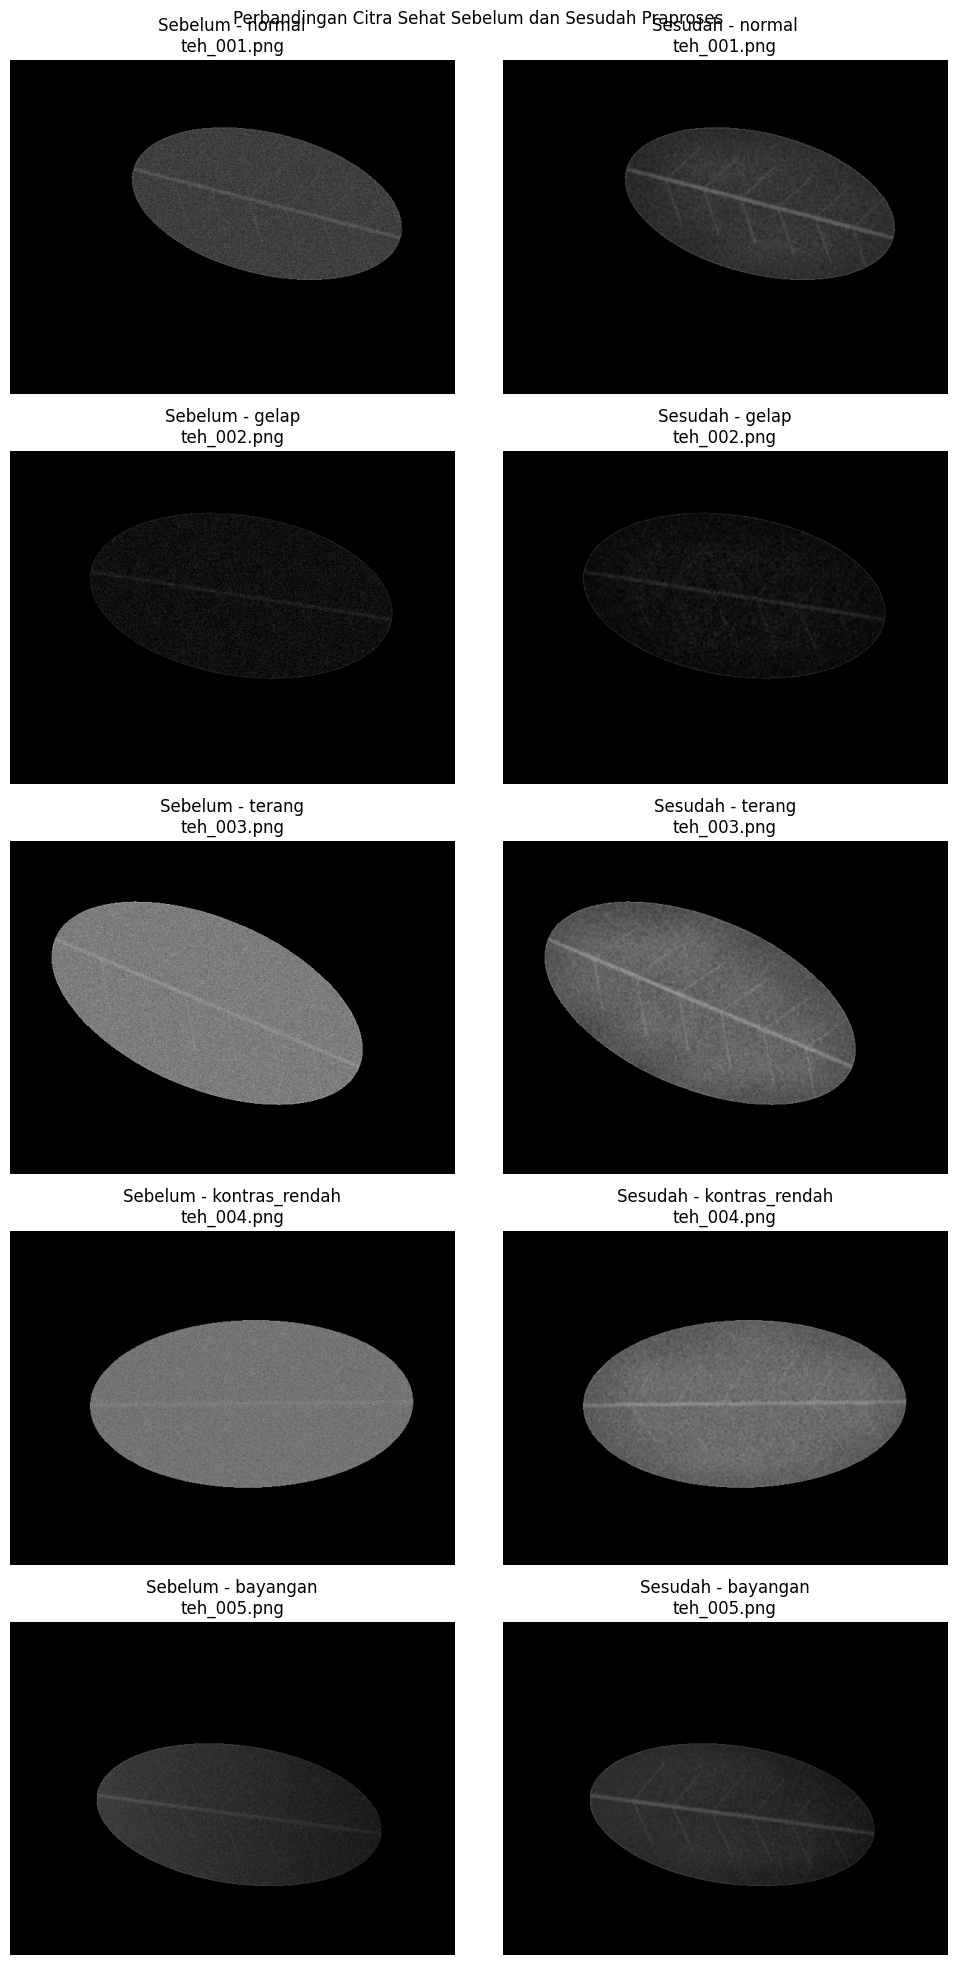

In [4]:
# Menampilkan perbandingan citra sehat
jumlah = len(panel)

fig, ax = plt.subplots(jumlah, 2, figsize=(10, 4 * jumlah))

if jumlah == 1:
    ax = np.array([ax])

for i, (kondisi, data) in enumerate(panel.items()):
    nama, sebelum, sesudah = data

    ax[i, 0].imshow(sebelum, cmap="gray", vmin=0, vmax=255)
    ax[i, 0].set_title(f"Sebelum - {kondisi}\n{nama}")
    ax[i, 0].axis("off")

    ax[i, 1].imshow(sesudah, cmap="gray", vmin=0, vmax=255)
    ax[i, 1].set_title(f"Sesudah - {kondisi}\n{nama}")
    ax[i, 1].axis("off")

plt.suptitle("Perbandingan Citra Sehat Sebelum dan Sesudah Praproses")
plt.tight_layout()
plt.savefig("../hasil/b5_panel_citra_sehat.png", dpi=200)
plt.show()

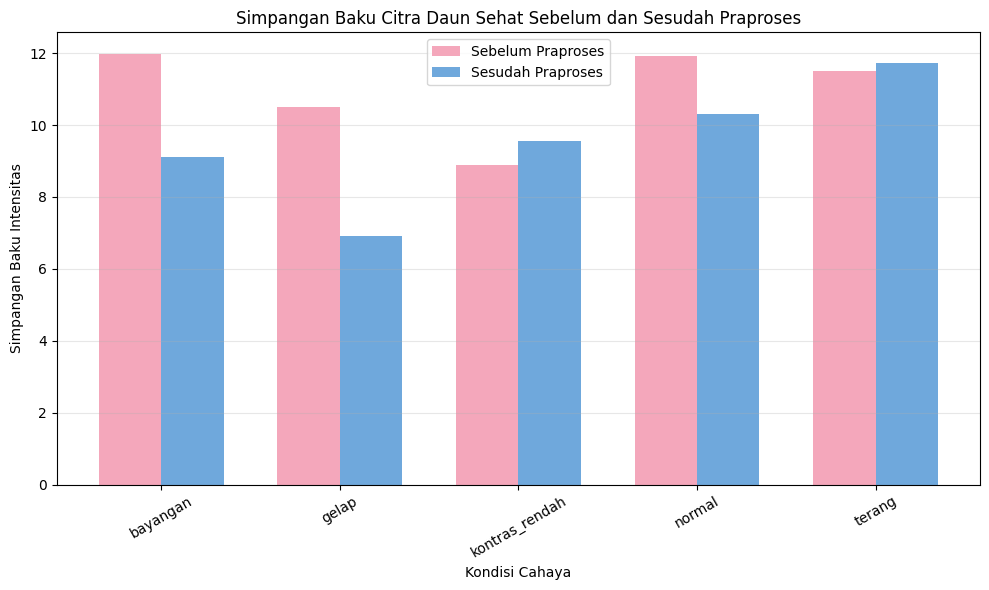

In [5]:
x = np.arange(len(ringkasan_sehat))
lebar = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - lebar/2,
    ringkasan_sehat["STD_sebelum"],
    lebar,
    label="Sebelum Praproses",
    color="#F4A7BB"
)

plt.bar(
    x + lebar/2,
    ringkasan_sehat["STD_sesudah"],
    lebar,
    label="Sesudah Praproses",
    color="#6FA8DC"
)

plt.title("Simpangan Baku Citra Daun Sehat Sebelum dan Sesudah Praproses")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("Simpangan Baku Intensitas")
plt.xticks(x, ringkasan_sehat.index, rotation=30)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../hasil/b5_grafik_citra_sehat.png", dpi=200)
plt.show()

FINAL

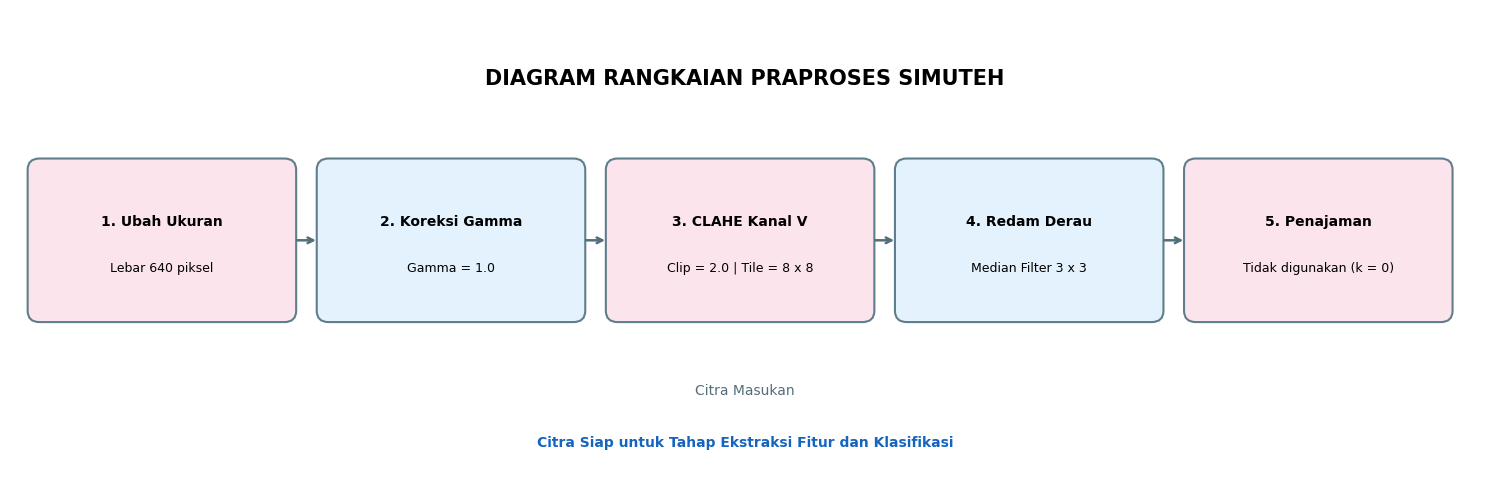

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

tahapan = [
    ("1. Ubah Ukuran", "Lebar 640 piksel"),
    ("2. Koreksi Gamma", "Gamma = 1.0"),
    ("3. CLAHE Kanal V", "Clip = 2.0 | Tile = 8 x 8"),
    ("4. Redam Derau", "Median Filter 3 x 3"),
    ("5. Penajaman", "Tidak digunakan (k = 0)")
]

fig, ax = plt.subplots(figsize=(15, 5))

ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")

warna = ["#FCE4EC", "#E3F2FD", "#FCE4EC", "#E3F2FD", "#FCE4EC"]

posisi = [0.3, 3.25, 6.2, 9.15, 12.1]

for i, (judul, isi) in enumerate(tahapan):
    x = posisi[i]

    kotak = FancyBboxPatch(
        (x, 1.8), 2.5, 1.5,
        boxstyle="round,pad=0.12",
        facecolor=warna[i],
        edgecolor="#607D8B",
        linewidth=1.5
    )

    ax.add_patch(kotak)

    ax.text(x + 1.25, 2.75, judul,
            ha="center", va="center",
            fontsize=10, fontweight="bold")

    ax.text(x + 1.25, 2.25, isi,
            ha="center", va="center",
            fontsize=9)

    if i < len(tahapan) - 1:
        ax.annotate(
            "",
            xy=(posisi[i+1] - 0.1, 2.55),
            xytext=(x + 2.6, 2.55),
            arrowprops=dict(arrowstyle="->", lw=1.8, color="#546E7A")
        )

ax.text(7.5, 4.2, "DIAGRAM RANGKAIAN PRAPROSES SIMUTEH",
        ha="center", fontsize=15, fontweight="bold")

ax.text(7.5, 0.9, "Citra Masukan",
        ha="center", fontsize=10, color="#546E7A")

ax.text(7.5, 0.35, "Citra Siap untuk Tahap Ekstraksi Fitur dan Klasifikasi",
        ha="center", fontsize=10, fontweight="bold", color="#1565C0")

plt.tight_layout()
plt.savefig("../hasil/b5_diagram_praproses_final.png",
            dpi=200, bbox_inches="tight")
plt.show()